# Tabular Pima Indians Diabetes - Dataset

In [5]:
#  Acquire and inspect real-world medical datasets across four different modalities.


import pandas as pd
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 150)

# Load dataset
df = pd.read_csv('diabetes.csv')

# Basic shape and structure
print("Shape:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nFirst 5 rows:\n", df.head())

# Statistical summary
print("\nSummary statistics:\n", df.describe())

# Missing values (pandas-native NaNs)
print("\nNull counts:\n", df.isnull().sum())

# Check for disguised missing values (0s in clinically implausible columns)
suspect_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
print("\nZero counts in clinically implausible columns:")
for col in suspect_cols:
    n_zero = (df[col] == 0).sum()
    print(f"  {col}: {n_zero} zeros ({n_zero/len(df)*100:.1f}%)")

# Check for suspicious repeated values (signs of prior imputation)
print("\nTop repeated values per suspect column:")
for col in suspect_cols:
    print(f"\n{col}:\n{df[col].value_counts().head(3)}")

# Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Class balance
print("\nOutcome distribution:\n", df['Outcome'].value_counts())
print(df['Outcome'].value_counts(normalize=True) * 100)

Shape: (768, 9)

Data types:
 Pregnancies                   int64
Glucose                       int64
BloodPressure               float64
SkinThickness                 int64
Insulin                     float64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

First 5 rows:
    Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  DiabetesPedigreeFunction  Age  Outcome
0            6      148           72.0             35    169.5  33.6                     0.627   50        1
1            1       85           66.0             29    102.5  26.6                     0.351   31        0
2            8      183           64.0             32    169.5  23.3                     0.672   32        1
3            1       89           66.0             23     94.0  28.1                     0.167   21        0
4            0      137           40.0             35    168.0  43.1   

In [6]:
# Apply modality-specific cleaning techniques, including healthcare-specific concerns like mplausible clinical values, PHI (Protected Health Information) removal, and imaging metadata anonymization.

import numpy as np

df_clean = df.copy()
print("Columns present:", list(df_clean.columns))
print("No direct/indirect identifier columns (name, ID, DOB, address) found.")
implausible_zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

for col in implausible_zero_cols:
    n_zero = (df_clean[col] == 0).sum()
    print(f"{col}: {n_zero} implausible zero values")


suspected_imputed_flags = pd.DataFrame(index=df_clean.index)
insulin_modes = df_clean['Insulin'].value_counts().head(2).index.tolist()
suspected_imputed_flags['Insulin_suspected_imputed'] = df_clean['Insulin'].isin(insulin_modes).astype(int)

# SkinThickness: one dominant repeated value
skin_mode = df_clean['SkinThickness'].value_counts().idxmax()
suspected_imputed_flags['SkinThickness_suspected_imputed'] = (df_clean['SkinThickness'] == skin_mode).astype(int)

print("\nSuspected pre-imputed value counts:")
print(suspected_imputed_flags.sum())
range_checks = {
    'Glucose': (40, 300),
    'BloodPressure': (30, 180),
    'BMI': (10, 70),
    'Age': (18, 100),
    'SkinThickness': (0, 100),
    'Insulin': (0, 900)
}
print("\nOut-of-plausible-range counts:")
for col, (low, high) in range_checks.items():
    n_out = ((df_clean[col] < low) | (df_clean[col] > high)).sum()
    print(f"  {col}: {n_out} rows outside [{low}, {high}]")


df_clean = pd.concat([df_clean, suspected_imputed_flags], axis=1)

Columns present: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
No direct/indirect identifier columns (name, ID, DOB, address) found.
Glucose: 0 implausible zero values
BloodPressure: 0 implausible zero values
SkinThickness: 0 implausible zero values
Insulin: 0 implausible zero values
BMI: 0 implausible zero values

Suspected pre-imputed value counts:
Insulin_suspected_imputed          374
SkinThickness_suspected_imputed    162
dtype: int64

Out-of-plausible-range counts:
  Glucose: 0 rows outside [40, 300]
  BloodPressure: 1 rows outside [30, 180]
  BMI: 0 rows outside [10, 70]
  Age: 0 rows outside [18, 100]
  SkinThickness: 0 rows outside [0, 100]
  Insulin: 0 rows outside [0, 900]


In [7]:
!pip install torch -q


In [8]:
# Preprocess each data type into a model-ready format (scaled tensors, token sequences, image tensors, signal windows).
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch

X = df_clean.drop(columns=['Outcome', 'Insulin_suspected_imputed', 'SkinThickness_suspected_imputed'])
y = df_clean['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).unsqueeze(1)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).unsqueeze(1)

print(X_train_tensor.shape, X_test_tensor.shape)
print(y_train_tensor.shape, y_test_tensor.shape)

torch.Size([614, 8]) torch.Size([154, 8])
torch.Size([614, 1]) torch.Size([154, 1])


In [10]:
# For Tabular data, perform Hypothesis Test, Chi-square Test and ANOVA.
from scipy import stats
import pandas as pd

numeric_cols = ['Pregnancies','Glucose','BloodPressure','SkinThickness','Insulin','BMI','DiabetesPedigreeFunction','Age']

ttest_results = []
for col in numeric_cols:
    group0 = df_clean[df_clean['Outcome']==0][col]
    group1 = df_clean[df_clean['Outcome']==1][col]
    t_stat, p_val = stats.ttest_ind(group0, group1, equal_var=False)
    ttest_results.append({'Feature': col, 't_stat': t_stat, 'p_value': p_val})

ttest_df = pd.DataFrame(ttest_results)
print(ttest_df)

df_clean['BMI_Category'] = pd.cut(df_clean['BMI'], bins=[0,18.5,25,30,100], labels=['Underweight','Normal','Overweight','Obese'])
contingency = pd.crosstab(df_clean['BMI_Category'], df_clean['Outcome'])
chi2, p_chi, dof, expected = stats.chi2_contingency(contingency)
print(contingency)
print(chi2, p_chi, dof)

df_clean['Age_Group'] = pd.cut(df_clean['Age'], bins=[0,25,35,45,100], labels=['Young','Adult','MiddleAge','Senior'])
groups = [df_clean[df_clean['Age_Group']==g]['Glucose'] for g in df_clean['Age_Group'].cat.categories]
f_stat, p_anova = stats.f_oneway(*groups)
print(f_stat, p_anova)

                    Feature     t_stat       p_value
0               Pregnancies  -5.906961  6.821926e-09
1                   Glucose -14.992113  8.301766e-42
2             BloodPressure  -4.904108  1.239931e-06
3             SkinThickness  -8.563820  1.104998e-16
4                   Insulin -10.559123  1.852039e-23
5                       BMI  -9.166799  1.017426e-18
6  DiabetesPedigreeFunction  -4.576812  6.100481e-06
7                       Age  -6.920738  1.201513e-11
Outcome         0    1
BMI_Category          
Underweight     4    0
Normal        101    7
Overweight    136   44
Obese         259  217
73.13331881767633 9.10165626851089e-16 3
20.607400024484672 7.566338984059345e-13


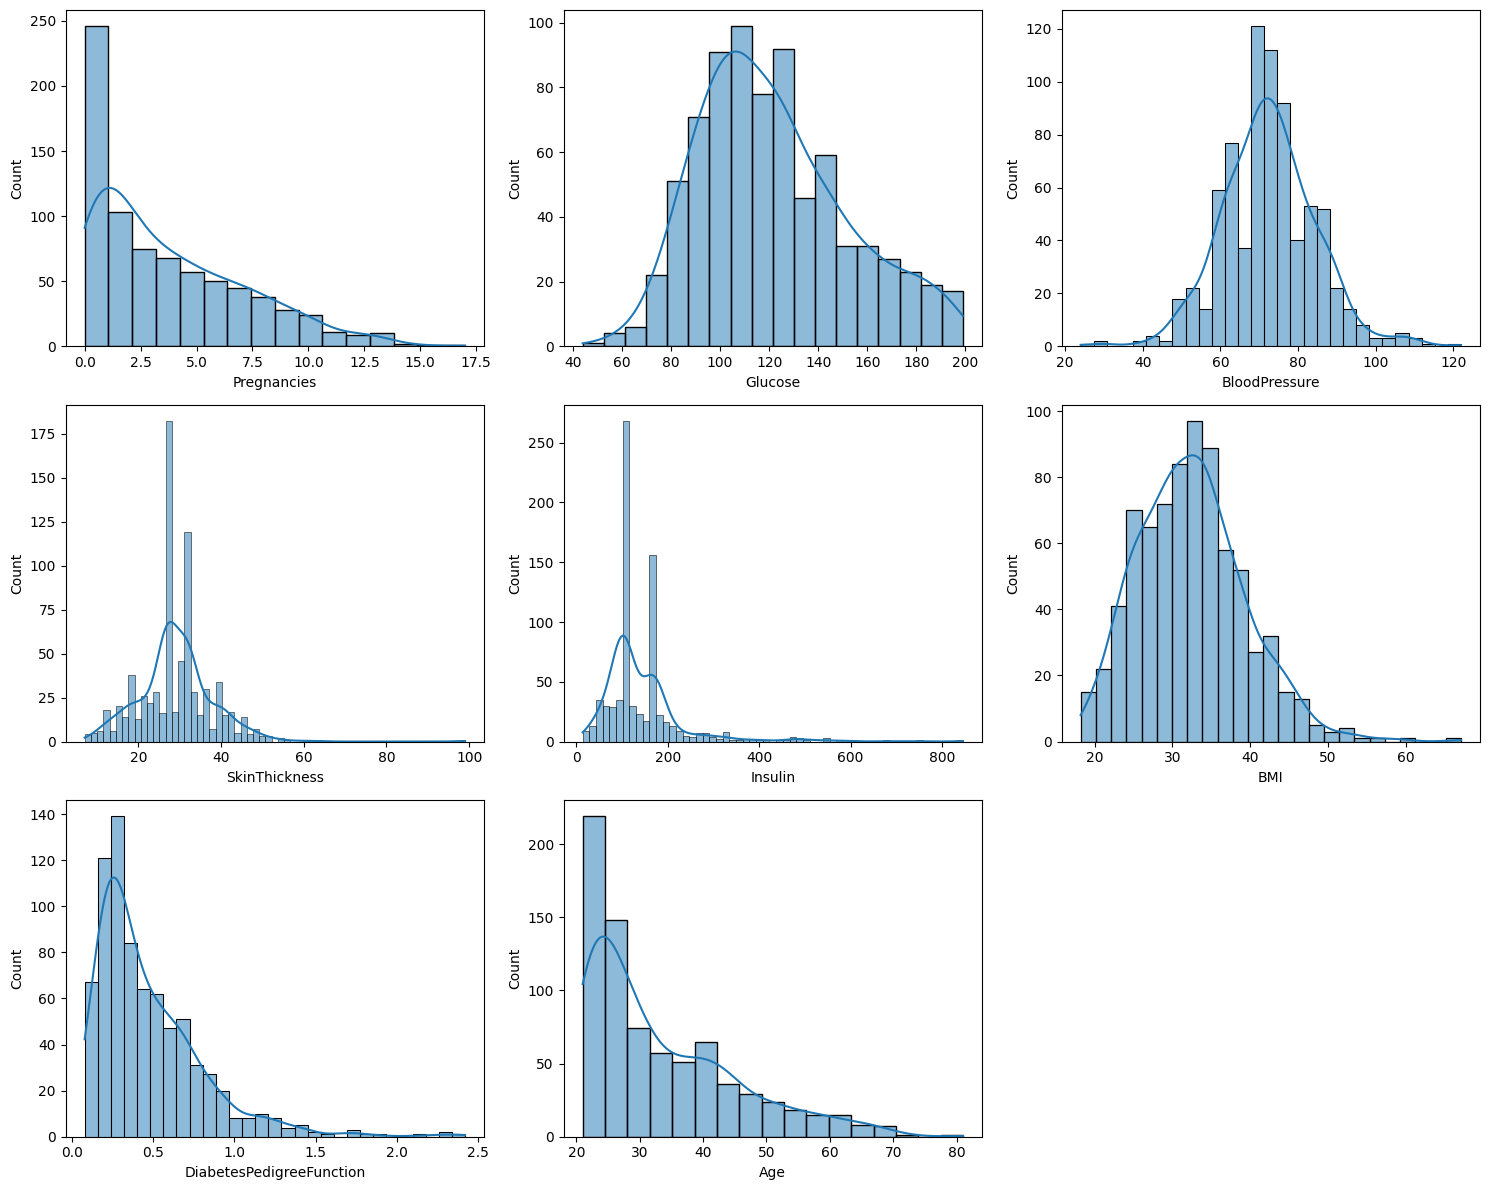

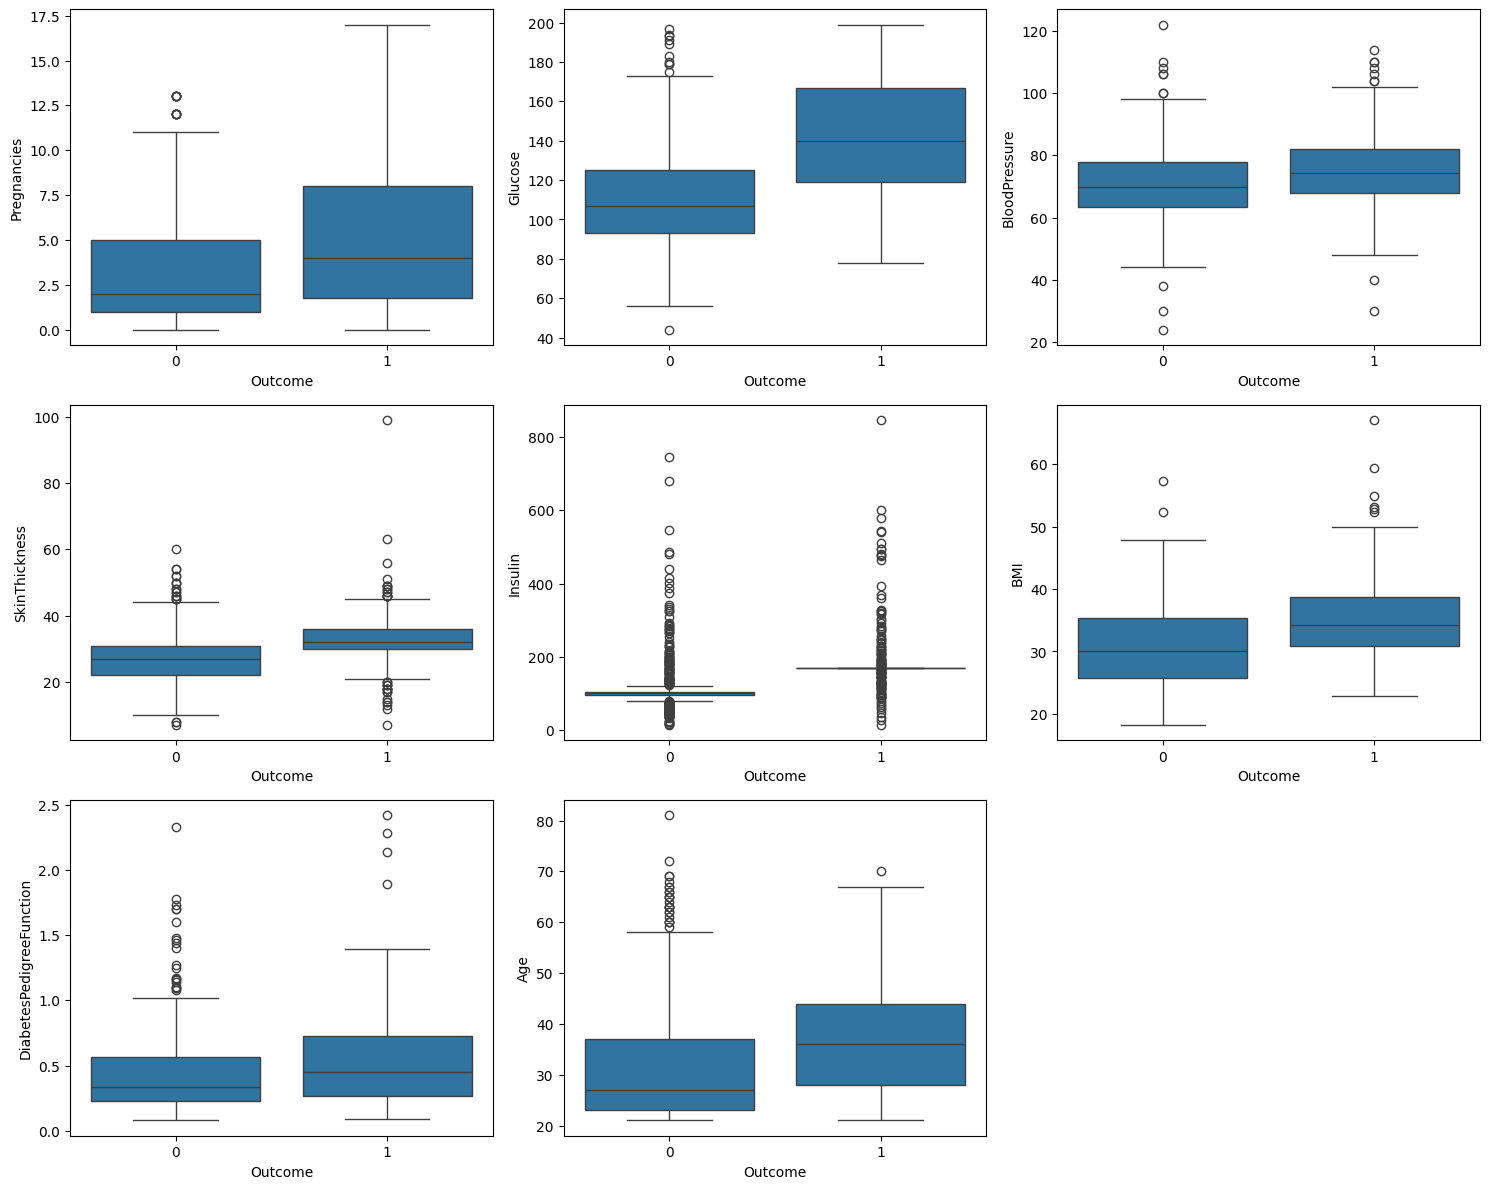

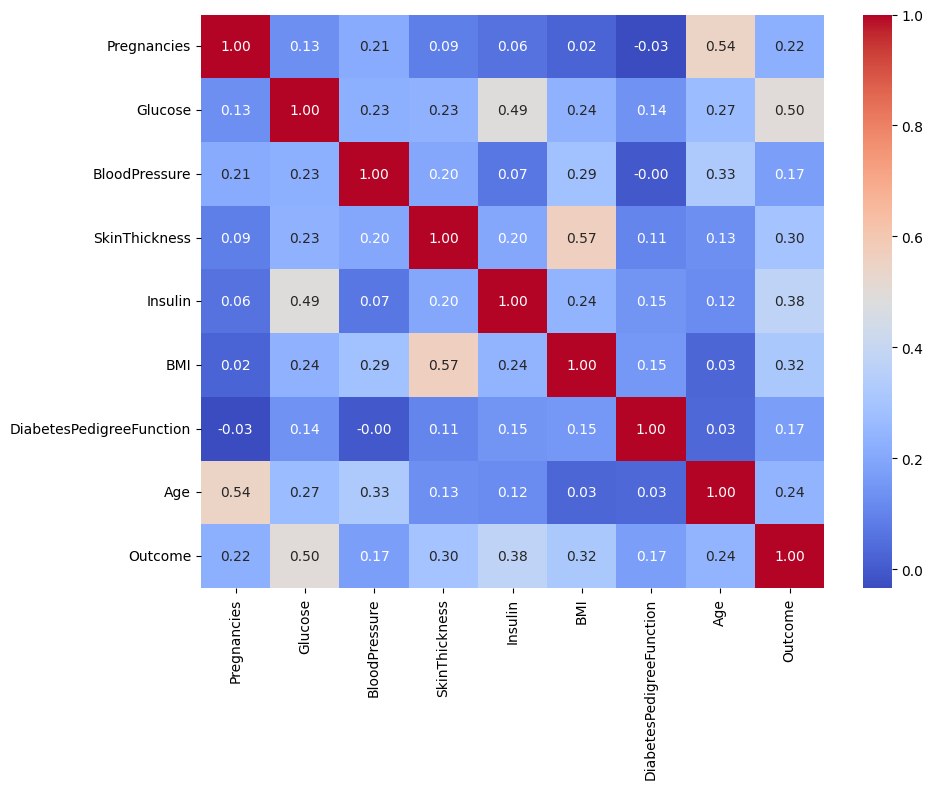

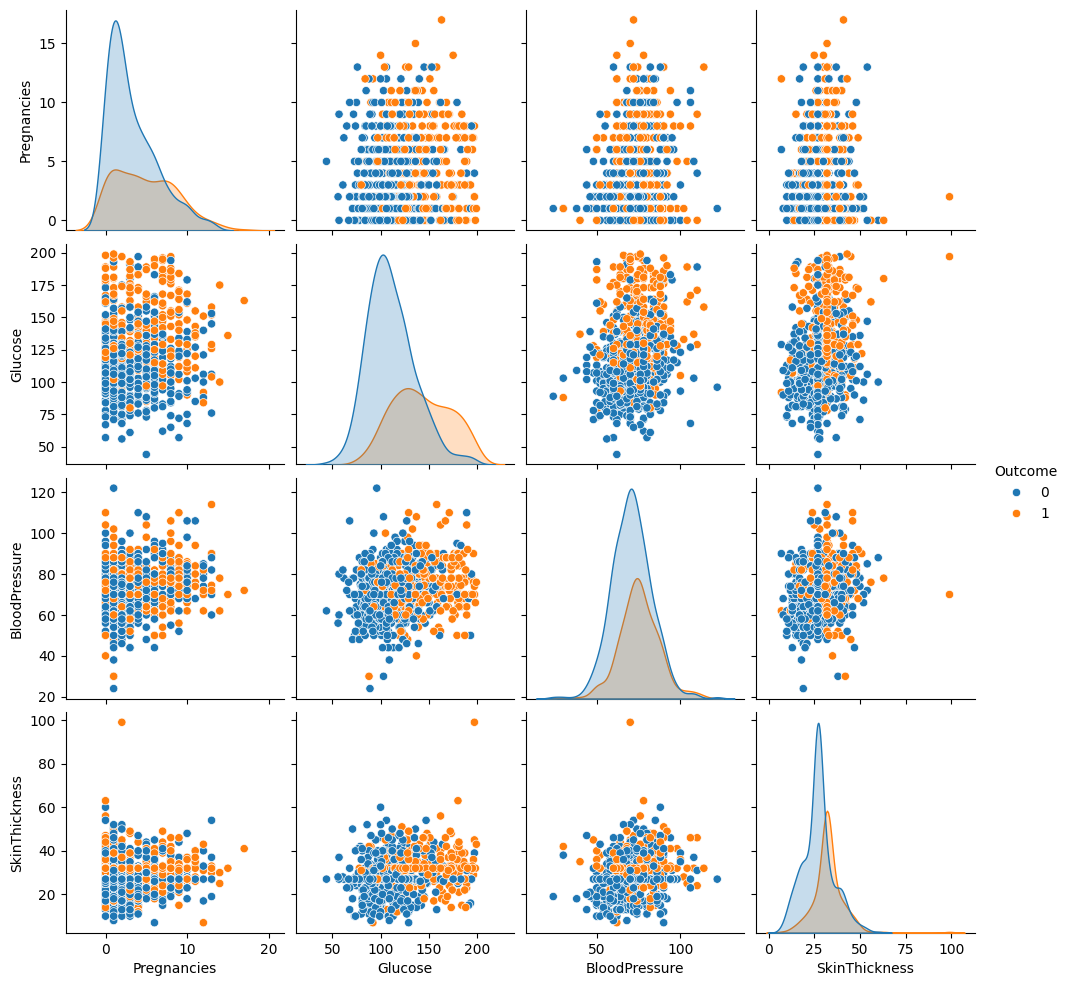

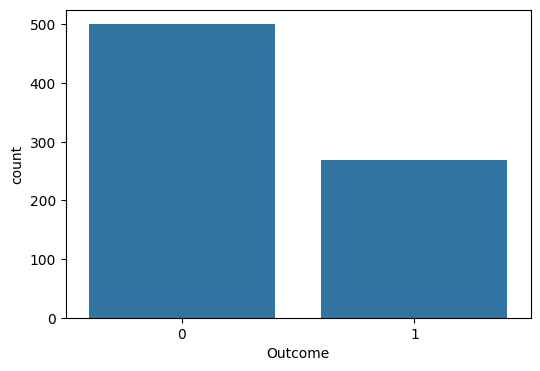

Pregnancies                 0.901674
Glucose                     0.532324
BloodPressure               0.140830
SkinThickness               0.817477
Insulin                     3.028046
BMI                         0.606416
DiabetesPedigreeFunction    1.919911
Age                         1.129597
dtype: float64
Pregnancies                  0.159220
Glucose                     -0.268105
BloodPressure                1.085427
SkinThickness                5.067565
Insulin                     13.852951
BMI                          0.915485
DiabetesPedigreeFunction     5.594954
Age                          0.643159
dtype: float64


In [11]:
# Perform exploratory data analysis (EDA) appropriate to each modality
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()
for i, col in enumerate(numeric_cols):
    sns.histplot(df_clean[col], kde=True, ax=axes[i])
axes[8].axis('off')
plt.tight_layout()
plt.savefig('eda_histograms.png')
plt.show()

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()
for i, col in enumerate(numeric_cols):
    sns.boxplot(x='Outcome', y=col, data=df_clean, ax=axes[i])
axes[8].axis('off')
plt.tight_layout()
plt.savefig('eda_boxplots.png')
plt.show()

plt.figure(figsize=(10,8))
corr = df_clean[numeric_cols + ['Outcome']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.tight_layout()
plt.savefig('eda_correlation.png')
plt.show()

sns.pairplot(df_clean, vars=numeric_cols[:4], hue='Outcome')
plt.savefig('eda_pairplot.png')
plt.show()

plt.figure(figsize=(6,4))
sns.countplot(x='Outcome', data=df_clean)
plt.savefig('eda_class_balance.png')
plt.show()

print(df_clean[numeric_cols].skew())
print(df_clean[numeric_cols].kurt())

In [12]:
# Apply Feature Engineering, Feature Selection & Extraction Noise Removal, Augmentation on relevant parts.
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
from imblearn.over_sampling import SMOTE

# --- Feature Engineering ---
df_fe = df_clean.copy()
df_fe['Glucose_BMI_Interaction'] = df_fe['Glucose'] * df_fe['BMI']
df_fe['Insulin_Glucose_Ratio'] = df_fe['Insulin'] / (df_fe['Glucose'] + 1)
df_fe['Age_Pregnancies_Interaction'] = df_fe['Age'] * df_fe['Pregnancies']

feature_cols = numeric_cols + ['Glucose_BMI_Interaction', 'Insulin_Glucose_Ratio', 'Age_Pregnancies_Interaction']

# --- Noise Removal (IQR-based outlier capping) ---
df_noise_removed = df_fe.copy()
for col in numeric_cols:
    Q1 = df_noise_removed[col].quantile(0.25)
    Q3 = df_noise_removed[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR
    df_noise_removed[col] = df_noise_removed[col].clip(lower, upper)

# --- Feature Selection (SelectKBest) ---
X_fs = df_noise_removed[feature_cols]
y_fs = df_noise_removed['Outcome']

selector = SelectKBest(score_func=f_classif, k=6)
X_selected = selector.fit_transform(X_fs, y_fs)
selected_features = X_fs.columns[selector.get_support()]
print(selected_features)

scores_df = pd.DataFrame({'Feature': feature_cols, 'F_Score': selector.scores_, 'p_value': selector.pvalues_})
print(scores_df.sort_values('F_Score', ascending=False))

# --- Feature Extraction (PCA) ---
scaler_pca = StandardScaler()
X_fs_scaled = scaler_pca.fit_transform(X_fs)

pca = PCA(n_components=5)
X_pca = pca.fit_transform(X_fs_scaled)
print(pca.explained_variance_ratio_)

# --- Augmentation (SMOTE for class imbalance) ---
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_fs, y_fs)
print(y_fs.value_counts())
print(y_resampled.value_counts())

Index(['Glucose', 'SkinThickness', 'Insulin', 'BMI', 'Glucose_BMI_Interaction', 'Insulin_Glucose_Ratio'], dtype='object')
                        Feature     F_Score       p_value
8       Glucose_BMI_Interaction  288.730351  3.435316e-55
4                       Insulin  256.258601  5.705498e-50
1                       Glucose  249.923949  6.226933e-49
5                           BMI   85.250276  2.524119e-19
3                 SkinThickness   83.752878  4.992750e-19
9         Insulin_Glucose_Ratio   50.320569  2.974937e-12
7                           Age   47.944757  9.284605e-12
10  Age_Pregnancies_Interaction   40.462166  3.445745e-10
0                   Pregnancies   39.106100  6.666771e-10
6      DiabetesPedigreeFunction   27.135876  2.439853e-07
2                 BloodPressure   25.066389  6.878266e-07
[0.32685511 0.20869363 0.12836032 0.09077732 0.08651454]
Outcome
0    500
1    268
Name: count, dtype: int64
Outcome
1    500
0    500
Name: count, dtype: int64


/Users/pankurajasaivardhan/Documents/AIH/aih/lib/python3.10/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/pankurajasaivardhan/Documents/AIH/aih/lib/python3.10/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/pankurajasaivardhan/Documents/AIH/aih/lib/python3.10/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: invalid value encountered in matmul
  X_transformed = X @ self.components_.T


## Textual- MTSamples Medical Transcriptions

In [13]:
# 1. Acquisition & Inspection
import pandas as pd

df_text = pd.read_csv('mtsamples.csv')
print(df_text.shape)
print(df_text.dtypes)
print(df_text.head())
print(df_text.isnull().sum())
print(df_text['medical_specialty'].value_counts())
print(df_text['transcription'].str.len().describe())
print(df_text.duplicated(subset=['transcription']).sum())

(4999, 6)
Unnamed: 0            int64
description          object
medical_specialty    object
sample_name          object
transcription        object
keywords             object
dtype: object
   Unnamed: 0                                        description            medical_specialty                                sample_name  \
0           0   A 23-year-old white female presents with comp...         Allergy / Immunology                         Allergic Rhinitis    
1           1           Consult for laparoscopic gastric bypass.                   Bariatrics   Laparoscopic Gastric Bypass Consult - 2    
2           2           Consult for laparoscopic gastric bypass.                   Bariatrics   Laparoscopic Gastric Bypass Consult - 1    
3           3                             2-D M-Mode. Doppler.     Cardiovascular / Pulmonary                    2-D Echocardiogram - 1    
4           4                                 2-D Echocardiogram   Cardiovascular / Pulmonary               

In [14]:
# 2. Cleaning (PHI removal + implausible/junk text)
import re

df_text_clean = df_text.dropna(subset=['transcription']).copy()
df_text_clean = df_text_clean.drop_duplicates(subset=['transcription'])
df_text_clean = df_text_clean.drop(columns=['Unnamed: 0'])

def remove_phi(text):
    text = re.sub(r'\b\d{1,2}[/-]\d{1,2}[/-]\d{2,4}\b', '[DATE]', text)
    text = re.sub(r'\bDr\.?\s+[A-Z][a-z]+\b', '[DOCTOR]', text)
    text = re.sub(r'\b[A-Z][a-z]+\s[A-Z][a-z]+, M\.?D\.?\b', '[DOCTOR]', text)
    text = re.sub(r'\b\d{3}[-.]?\d{3}[-.]?\d{4}\b', '[PHONE]', text)
    text = re.sub(r'\bMRN[:#]?\s*\d+\b', '[MRN]', text, flags=re.IGNORECASE)
    text = re.sub(r'\b\d{3}-\d{2}-\d{4}\b', '[SSN]', text)
    return text

df_text_clean['transcription'] = df_text_clean['transcription'].apply(remove_phi)

def clean_text(text):
    text = text.lower()
    text = re.sub(r'\s+', ' ', text)
    text = re.sub(r'[^a-z0-9\s\[\]]', '', text)
    return text.strip()

df_text_clean['transcription_clean'] = df_text_clean['transcription'].apply(clean_text)
print(df_text_clean.shape)

(2357, 6)


In [15]:
# 3. Preprocessing → model-ready format (token sequences)
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

le = LabelEncoder()
y_text = le.fit_transform(df_text_clean['medical_specialty'])

tokenizer = Tokenizer(num_words=10000, oov_token='<OOV>')
tokenizer.fit_on_texts(df_text_clean['transcription_clean'])
sequences = tokenizer.texts_to_sequences(df_text_clean['transcription_clean'])
padded_sequences = pad_sequences(sequences, maxlen=300, padding='post', truncating='post')

print(padded_sequences.shape)
print(len(tokenizer.word_index))

(2357, 300)
43938


# (Hypothesis Test / Chi-square / ANOVA — skip, assignment specifies those for Tabular only.)

In [48]:
!pip install wordcloud -q

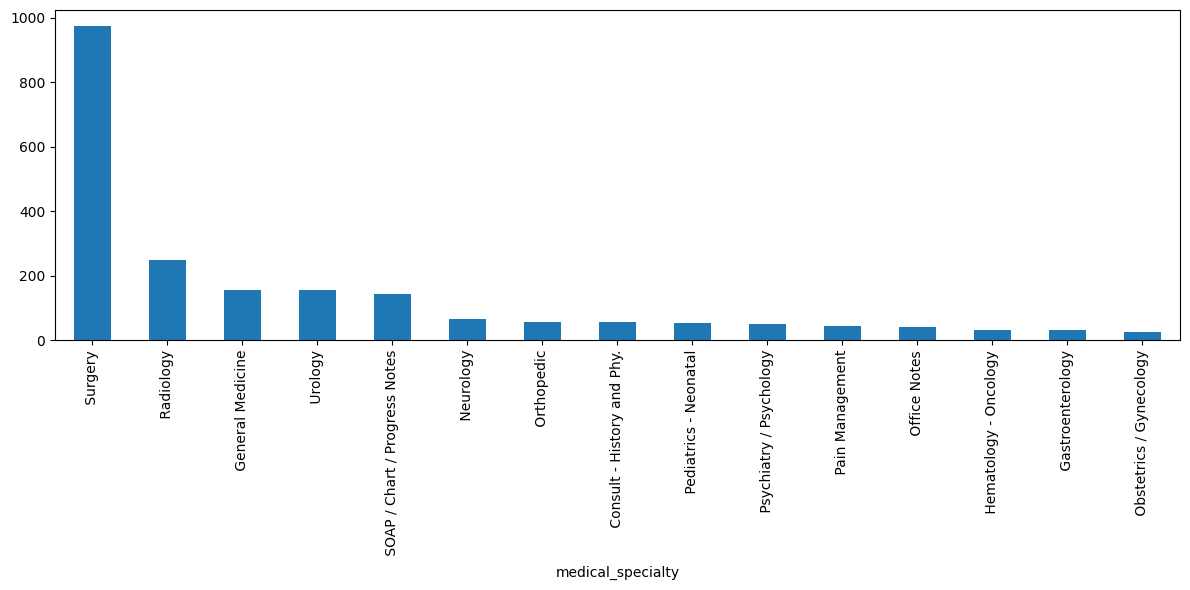

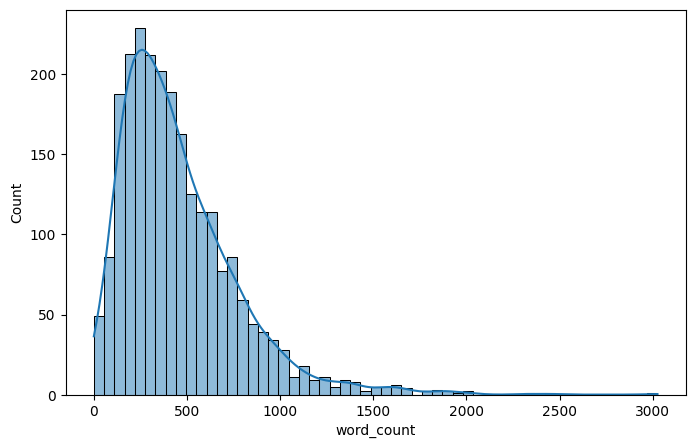

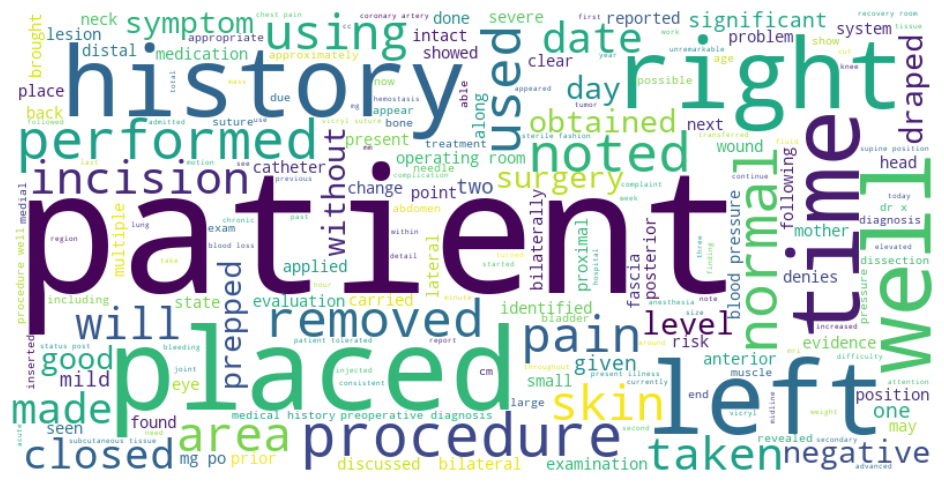

In [49]:
# 4. EDA (text-appropriate)
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

plt.figure(figsize=(12,6))
df_text_clean['medical_specialty'].value_counts().head(15).plot(kind='bar')
plt.tight_layout()
plt.savefig('text_specialty_counts.png')
plt.show()

df_text_clean['word_count'] = df_text_clean['transcription_clean'].apply(lambda x: len(x.split()))
plt.figure(figsize=(8,5))
sns.histplot(df_text_clean['word_count'], kde=True)
plt.savefig('text_wordcount_dist.png')
plt.show()

all_text = ' '.join(df_text_clean['transcription_clean'].sample(500, random_state=42))
wc = WordCloud(width=800, height=400, background_color='white').generate(all_text)
plt.figure(figsize=(12,6))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.savefig('text_wordcloud.png')
plt.show()

In [50]:
!pip install nltk -q

In [51]:
# 5. Feature Engineering / Selection / Extraction / Noise Removal
from sklearn.feature_extraction.text import TfidfVectorizer
from nltk.corpus import stopwords
import nltk
nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

def remove_noise(text):
    tokens = [w for w in text.split() if w not in stop_words and len(w) > 2]
    return ' '.join(tokens)

df_text_clean['transcription_noise_removed'] = df_text_clean['transcription_clean'].apply(remove_noise)

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1,2))
X_tfidf = tfidf.fit_transform(df_text_clean['transcription_noise_removed'])
print(X_tfidf.shape)

feature_names = tfidf.get_feature_names_out()
scores = X_tfidf.sum(axis=0).A1
top_features = pd.DataFrame({'term': feature_names, 'score': scores}).sort_values('score', ascending=False).head(20)
print(top_features)

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/pankurajasaivardhan/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


(2357, 5000)
           term       score
3129    patient  137.485623
3802      right   88.942350
2369       left   85.778561
1986    history   78.379974
2879     normal   66.069619
3299     placed   60.351327
3066       pain   54.335001
3470  procedure   54.245752
4899       well   47.521996
1178  diagnosis   40.766471
4743      using   40.753070
200        also   39.861713
4944    without   39.483666
521       blood   38.586332
2904      noted   38.053153
4533       time   37.685305
2101   incision   36.033824
4736       used   35.540408
3704    removed   35.445395
4102       skin   35.323211


## Image Chest X-Ray - (Pneumonia) Dataset

In [52]:
!pip install kagglehub -q

In [53]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

print("Path to dataset files:", path)

Path to dataset files: /Users/pankurajasaivardhan/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2


In [54]:
# Acquisition & Inspection)
import os

base_path = os.path.join(path, 'chest_xray')
print(os.listdir(base_path))

for split in ['train', 'test', 'val']:
    split_path = os.path.join(base_path, split)
    for cls in ['NORMAL', 'PNEUMONIA']:
        cls_path = os.path.join(split_path, cls)
        n_files = len(os.listdir(cls_path))
        print(f"{split}/{cls}: {n_files} images")

import random
from PIL import Image

sample_normal = os.path.join(base_path, 'train', 'NORMAL', os.listdir(os.path.join(base_path, 'train', 'NORMAL'))[0])
sample_pneumonia = os.path.join(base_path, 'train', 'PNEUMONIA', os.listdir(os.path.join(base_path, 'train', 'PNEUMONIA'))[0])

img_n = Image.open(sample_normal)
img_p = Image.open(sample_pneumonia)

print("NORMAL sample:", img_n.size, img_n.mode)
print("PNEUMONIA sample:", img_p.size, img_p.mode)

sizes = []
for cls in ['NORMAL', 'PNEUMONIA']:
    files = os.listdir(os.path.join(base_path, 'train', cls))[:50]
    for f in files:
        img = Image.open(os.path.join(base_path, 'train', cls, f))
        sizes.append(img.size)

import pandas as pd
sizes_df = pd.DataFrame(sizes, columns=['width', 'height'])
print(sizes_df.describe())

['test', 'chest_xray', '__MACOSX', 'train', 'val']
train/NORMAL: 1341 images
train/PNEUMONIA: 3875 images
test/NORMAL: 234 images
test/PNEUMONIA: 390 images
val/NORMAL: 8 images
val/PNEUMONIA: 8 images
NORMAL sample: (2359, 2234) L
PNEUMONIA sample: (1048, 736) L
             width       height
count   100.000000   100.000000
mean   1463.330000  1133.100000
std     402.017138   478.684698
min     384.000000   127.000000
25%    1191.000000   802.000000
50%    1400.000000  1052.500000
75%    1705.000000  1358.750000
max    2373.000000  2663.000000


In [55]:
# Cleaning (imaging metadata anonymization + implausible value checks)
from PIL import Image
import os

def check_and_strip_metadata(img_path):
    img = Image.open(img_path)
    exif_data = img._getexif() if hasattr(img, '_getexif') else None
    has_metadata = exif_data is not None
    img_clean = Image.new(img.mode, img.size)
    img_clean.putdata(list(img.getdata()))
    return has_metadata, img_clean

metadata_flags = []
for cls in ['NORMAL', 'PNEUMONIA']:
    files = os.listdir(os.path.join(base_path, 'train', cls))[:100]
    for f in files:
        fpath = os.path.join(base_path, 'train', cls, f)
        has_meta, _ = check_and_strip_metadata(fpath)
        metadata_flags.append(has_meta)

print(f"Images with embedded EXIF/metadata: {sum(metadata_flags)} / {len(metadata_flags)}")

import numpy as np

def check_implausible_image(img_path):
    img = np.array(Image.open(img_path).convert('L'))
    mean_intensity = img.mean()
    std_intensity = img.std()
    is_blank = std_intensity < 5
    is_corrupt = img.shape[0] < 50 or img.shape[1] < 50
    return mean_intensity, std_intensity, is_blank, is_corrupt

checks = []
for cls in ['NORMAL', 'PNEUMONIA']:
    files = os.listdir(os.path.join(base_path, 'train', cls))[:100]
    for f in files:
        fpath = os.path.join(base_path, 'train', cls, f)
        mean_i, std_i, blank, corrupt = check_implausible_image(fpath)
        checks.append({'class': cls, 'file': f, 'mean': mean_i, 'std': std_i, 'blank': blank, 'corrupt': corrupt})

checks_df = pd.DataFrame(checks)
print(checks_df[['blank','corrupt']].sum())
print(checks_df.groupby('class')[['mean','std']].describe())

/var/folders/5c/8z7vyvz92nv0y0r62jyssfnc0000gn/T/ipykernel_67266/3987731087.py:10: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  img_clean.putdata(list(img.getdata()))


Images with embedded EXIF/metadata: 105 / 200
blank      0
corrupt    0
dtype: int64
            mean                                                                                     std                                   \
           count        mean        std        min         25%         50%         75%        max  count       mean        std        min   
class                                                                                                                                       
NORMAL     100.0  122.332471  14.820633  83.775239  112.847097  122.390257  129.967547  159.59159  100.0  61.770877   5.494815  49.188007   
PNEUMONIA  100.0  123.657325  19.880269  69.804242  112.376926  124.015162  136.003535  169.11284  100.0  54.063747  10.771487  25.003930   

                                                       
                 25%        50%        75%        max  
class                                                  
NORMAL     57.589023  61.826507  65.53329

In [56]:
!pip install torchvision -q

In [57]:
# Preprocess into model-ready image tensors
import torch
import numpy as np
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import os

IMG_SIZE = 224

def preprocess_image(img_path):
    img = Image.open(img_path).convert('L')
    img = img.resize((IMG_SIZE, IMG_SIZE))
    arr = np.array(img, dtype=np.float32) / 255.0
    arr = (arr - 0.5) / 0.5
    tensor = torch.from_numpy(arr).unsqueeze(0)
    return tensor

class ChestXrayDataset(Dataset):
    def __init__(self, root_dir):
        self.samples = []
        for label, cls in enumerate(['NORMAL', 'PNEUMONIA']):
            cls_dir = os.path.join(root_dir, cls)
            for fname in os.listdir(cls_dir):
                self.samples.append((os.path.join(cls_dir, fname), label))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        tensor = preprocess_image(img_path)
        return tensor, label

train_dataset = ChestXrayDataset(os.path.join(base_path, 'train'))
test_dataset = ChestXrayDataset(os.path.join(base_path, 'test'))

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

sample_img, sample_label = train_dataset[0]
print(sample_img.shape, sample_label)
print(len(train_dataset), len(test_dataset))

torch.Size([1, 224, 224]) 0
5216 624


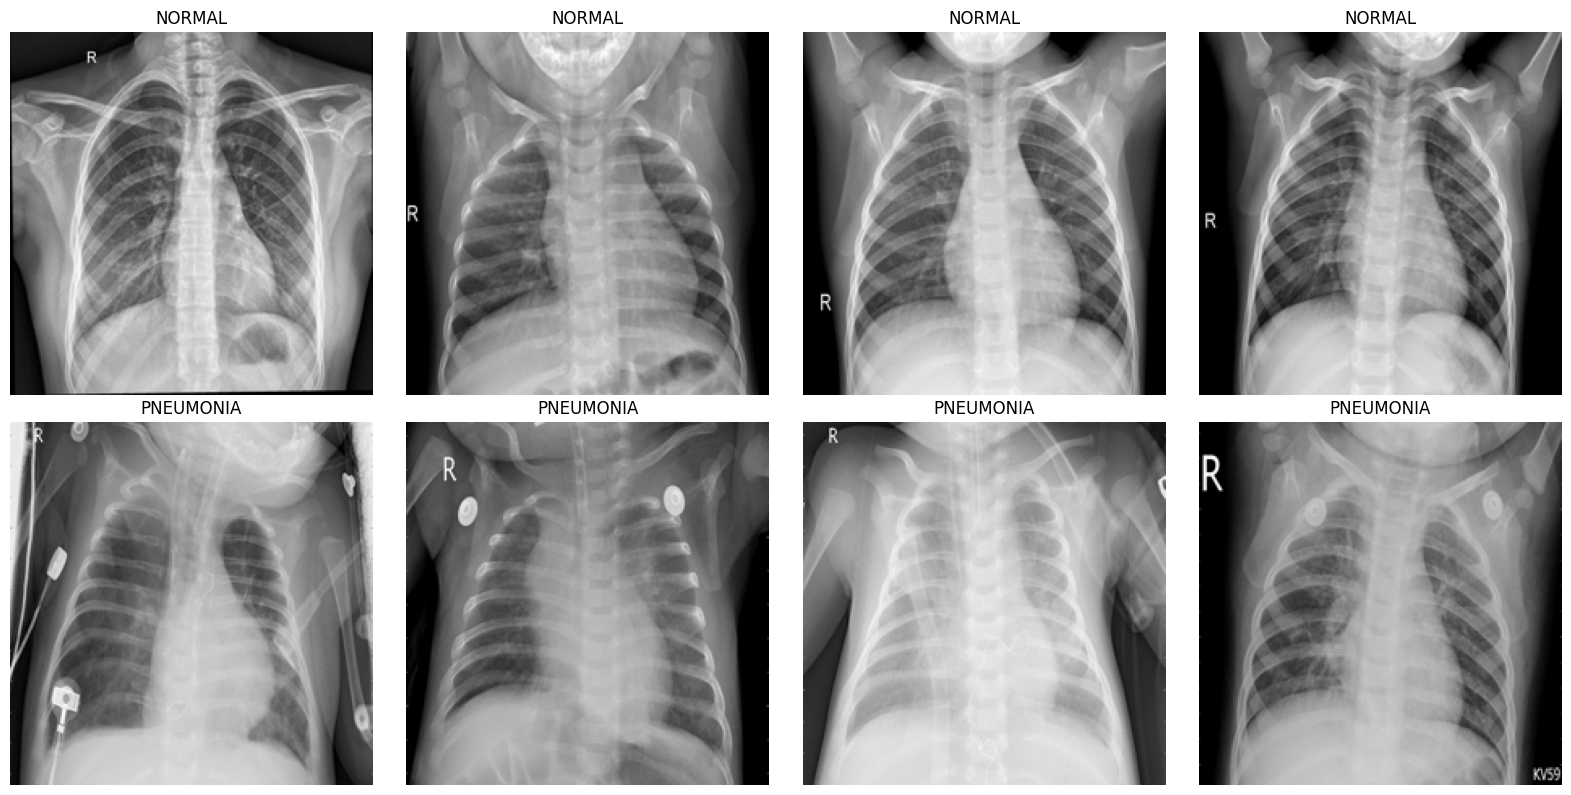

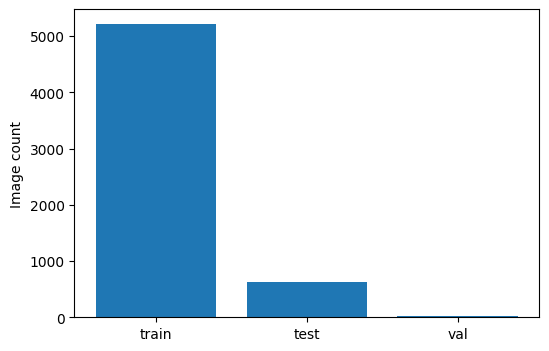

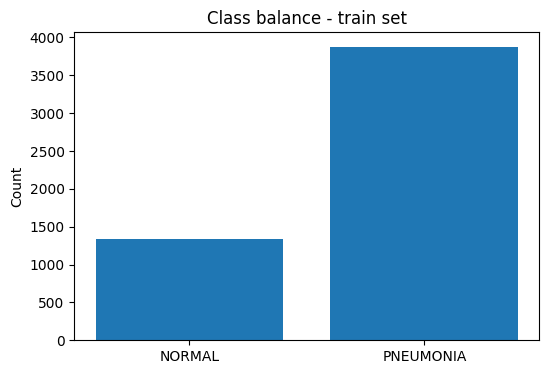

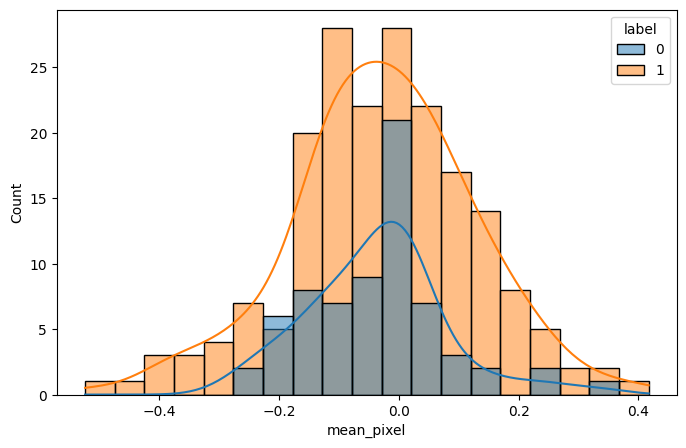

       count      mean       std       min       25%       50%       75%       max
label                                                                             
0       68.0 -0.037291  0.113674 -0.271734 -0.106752 -0.020697  0.016951  0.331174
1      193.0 -0.027787  0.153967 -0.524011 -0.116168 -0.026211  0.070719  0.417147


In [58]:
#  EDA (image-appropriate)
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i in range(4):
    img, label = train_dataset[i]
    axes[0, i].imshow(img.squeeze(), cmap='gray')
    axes[0, i].set_title(['NORMAL','PNEUMONIA'][label])
    axes[0, i].axis('off')

pneumonia_start = 1341
for i in range(4):
    img, label = train_dataset[pneumonia_start + i]
    axes[1, i].imshow(img.squeeze(), cmap='gray')
    axes[1, i].set_title(['NORMAL','PNEUMONIA'][label])
    axes[1, i].axis('off')

plt.tight_layout()
plt.savefig('xray_samples.png')
plt.show()

plt.figure(figsize=(6,4))
plt.bar(['train','test','val'], [5216, 624, 16])
plt.ylabel('Image count')
plt.savefig('xray_split_sizes.png')
plt.show()

plt.figure(figsize=(6,4))
plt.bar(['NORMAL','PNEUMONIA'], [1341, 3875])
plt.ylabel('Count')
plt.title('Class balance - train set')
plt.savefig('xray_class_balance.png')
plt.show()

pixel_means = []
labels_list = []
for i in range(0, len(train_dataset), 20):
    img, label = train_dataset[i]
    pixel_means.append(img.mean().item())
    labels_list.append(label)

import pandas as pd
pm_df = pd.DataFrame({'mean_pixel': pixel_means, 'label': labels_list})
plt.figure(figsize=(8,5))
import seaborn as sns
sns.histplot(data=pm_df, x='mean_pixel', hue='label', kde=True)
plt.savefig('xray_pixel_dist.png')
plt.show()

print(pm_df.groupby('label')['mean_pixel'].describe())

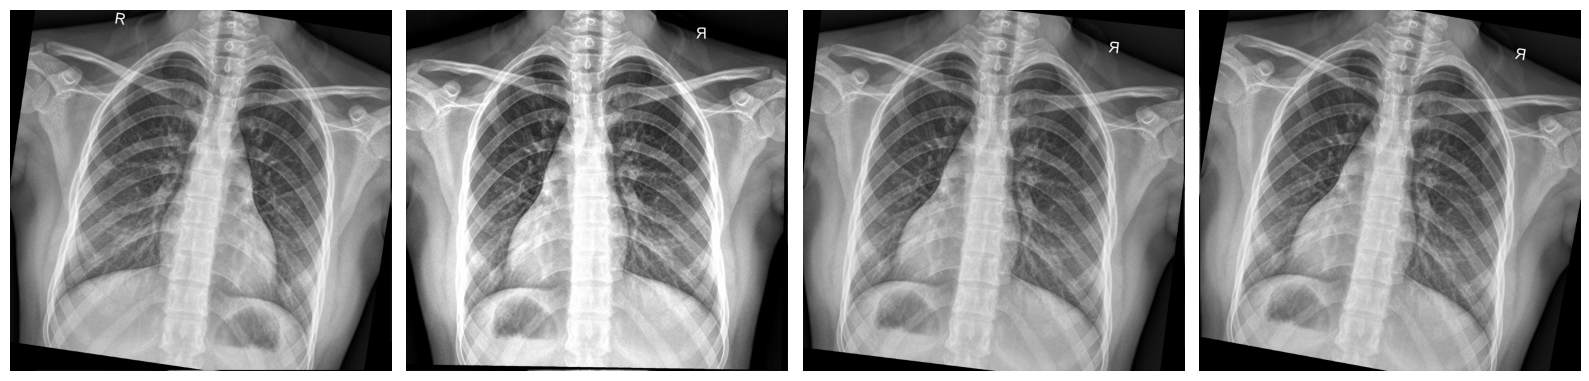

In [59]:
import numpy as np
from PIL import Image, ImageEnhance
import random

def augment_image(img_pil):
    img = img_pil.copy()

    angle = random.uniform(-10, 10)
    img = img.rotate(angle)

    if random.random() > 0.5:
        img = img.transpose(Image.FLIP_LEFT_RIGHT)

    arr = np.array(img)
    tx = random.randint(-10, 10)
    ty = random.randint(-10, 10)
    arr = np.roll(arr, tx, axis=1)
    arr = np.roll(arr, ty, axis=0)
    img = Image.fromarray(arr)

    brightness = ImageEnhance.Brightness(img)
    img = brightness.enhance(random.uniform(0.8, 1.2))

    contrast = ImageEnhance.Contrast(img)
    img = contrast.enhance(random.uniform(0.8, 1.2))

    return img

img_pil = Image.open(sample_path).convert('L')
fig, axes = plt.subplots(1, 4, figsize=(16,4))
for i in range(4):
    aug_img = augment_image(img_pil)
    axes[i].imshow(aug_img, cmap='gray')
    axes[i].axis('off')
plt.tight_layout()
plt.savefig('xray_augmented_samples.png')
plt.show()

## Signal MIT-BIH Arrhythmia Database (ECG)

In [60]:
!pip install wfdb -q

In [61]:
import wfdb

wfdb.dl_database('mitdb', dl_dir='mitdb_data')

Generating record list for: 100
Generating record list for: 101
Generating record list for: 102
Generating record list for: 103
Generating record list for: 104
Generating record list for: 105
Generating record list for: 106
Generating record list for: 107
Generating record list for: 108
Generating record list for: 109
Generating record list for: 111
Generating record list for: 112
Generating record list for: 113
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 117
Generating record list for: 118
Generating record list for: 119
Generating record list for: 121
Generating record list for: 122
Generating record list for: 123
Generating record list for: 124
Generating record list for: 200
Generating record list for: 201
Generating record list for: 202
Generating record list for: 203
Generating record list for: 205
Generating record list for: 207
Generating record list for: 208
Generating record list for: 209
Generati

In [62]:
# Acquisition & Inspection.
import wfdb
import os

record_names = sorted(set([f.split('.')[0] for f in os.listdir('mitdb_data') if f.endswith('.dat')]))
print(f"Total records: {len(record_names)}")
print(record_names)

record = wfdb.rdrecord('mitdb_data/100')
print("Signal shape:", record.p_signal.shape)
print("Sampling frequency:", record.fs)
print("Signal names:", record.sig_name)
print("Units:", record.units)
print("Duration (sec):", record.p_signal.shape[0] / record.fs)

annotation = wfdb.rdann('mitdb_data/100', 'atr')
print("Number of annotations:", len(annotation.sample))
print("Annotation symbols (first 20):", annotation.symbol[:20])

import numpy as np
unique_symbols, counts = np.unique(annotation.symbol, return_counts=True)
for sym, cnt in zip(unique_symbols, counts):
    print(f"{sym}: {cnt}")

Total records: 48
['100', '101', '102', '103', '104', '105', '106', '107', '108', '109', '111', '112', '113', '114', '115', '116', '117', '118', '119', '121', '122', '123', '124', '200', '201', '202', '203', '205', '207', '208', '209', '210', '212', '213', '214', '215', '217', '219', '220', '221', '222', '223', '228', '230', '231', '232', '233', '234']
Signal shape: (650000, 2)
Sampling frequency: 360
Signal names: ['MLII', 'V5']
Units: ['mV', 'mV']
Duration (sec): 1805.5555555555557
Number of annotations: 2274
Annotation symbols (first 20): ['+', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'A', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N']
+: 1
A: 33
N: 2239
V: 1


In [63]:
# Cleaning (implausible values + PHI check)
import numpy as np

def check_signal_quality(record_name):
    record = wfdb.rdrecord(f'mitdb_data/{record_name}')
    signal = record.p_signal
    n_nan = np.isnan(signal).sum()
    n_flat = 0
    for lead in range(signal.shape[1]):
        diffs = np.diff(signal[:, lead])
        flat_regions = np.sum(diffs == 0)
        n_flat += flat_regions
    saturated = np.sum((signal >= np.nanmax(signal) * 0.99) | (signal <= np.nanmin(signal) * 0.99))
    return n_nan, n_flat, saturated, signal.min(), signal.max()

quality_report = []
for rec in record_names[:10]:
    n_nan, n_flat, saturated, smin, smax = check_signal_quality(rec)
    quality_report.append({
        'record': rec, 'nan_count': n_nan, 'flat_samples': n_flat,
        'saturated_samples': saturated, 'min_mV': smin, 'max_mV': smax
    })

import pandas as pd
quality_df = pd.DataFrame(quality_report)
print(quality_df)

print("\nPHI check — MIT-BIH headers:")
record_full = wfdb.rdrecord('mitdb_data/100')
print(record_full.__dict__.keys())
print("Comments field (may contain age/sex, no direct identifiers):", record_full.comments)

  record  nan_count  flat_samples  saturated_samples  min_mV  max_mV
0    100          0        205828                  4  -2.715   1.435
1    101          0        207546                 19  -3.175   2.420
2    102          0        158790                 65  -3.370   2.535
3    103          0        184429                284  -5.120   5.115
4    104          0        178579                  2  -1.935   1.975
5    105          0        163860                 18  -3.715   3.000
6    106          0        137370                  6  -2.665   2.570
7    107          0        106163                  5  -3.375   3.465
8    108          0        152524                 27  -4.490   3.150
9    109          0        164636                  5  -3.195   3.130

PHI check — MIT-BIH headers:
dict_keys(['record_name', 'n_sig', 'fs', 'counter_freq', 'base_counter', 'sig_len', 'base_time', 'base_date', 'comments', 'sig_name', 'p_signal', 'd_signal', 'e_p_signal', 'e_d_signal', 'file_name', 'fmt', 'samp

In [64]:
# Preprocess into model-ready format (signal windows)
import numpy as np
from scipy.signal import butter, filtfilt

def bandpass_filter(signal, fs, lowcut=0.5, highcut=40, order=4):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype='band')
    filtered = filtfilt(b, a, signal)
    return filtered

def create_windows(record_name, window_size=360, step=180):
    record = wfdb.rdrecord(f'mitdb_data/{record_name}')
    annotation = wfdb.rdann(f'mitdb_data/{record_name}', 'atr')
    signal = record.p_signal[:, 0]
    filtered_signal = bandpass_filter(signal, record.fs)

    windows = []
    labels = []
    for beat_idx, beat_sample in enumerate(annotation.sample):
        start = beat_sample - window_size // 2
        end = beat_sample + window_size // 2
        if start >= 0 and end <= len(filtered_signal):
            windows.append(filtered_signal[start:end])
            labels.append(annotation.symbol[beat_idx])
    return np.array(windows), np.array(labels)

all_windows = []
all_labels = []
for rec in record_names[:10]:
    w, l = create_windows(rec)
    all_windows.append(w)
    all_labels.append(l)

X_signal = np.concatenate(all_windows, axis=0)
y_signal = np.concatenate(all_labels, axis=0)

print("X_signal shape:", X_signal.shape)
print("Unique labels:", np.unique(y_signal, return_counts=True))

import torch
valid_mask = np.isin(y_signal, ['N', 'A', 'V', 'L', 'R'])
X_signal_valid = X_signal[valid_mask]
y_signal_valid = y_signal[valid_mask]

label_map = {'N': 0, 'A': 1, 'V': 2, 'L': 3, 'R': 4}
y_encoded = np.array([label_map[l] for l in y_signal_valid])

X_tensor = torch.tensor(X_signal_valid, dtype=torch.float32).unsqueeze(1)
y_tensor = torch.tensor(y_encoded, dtype=torch.long)

print("Final tensor shape:", X_tensor.shape)
print("Label distribution:", np.unique(y_encoded, return_counts=True))

X_signal shape: (22008, 360)
Unique labels: (array(['+', '/', 'A', 'F', 'L', 'N', 'Q', 'V', 'f', 'j', 'x', '|', '~'],
      dtype='<U1'), array([   89,  5481,    42,     4,  2490, 12210,    25,   682,   722,
           1,    11,    42,   209]))
Final tensor shape: torch.Size([15424, 1, 360])
Label distribution: (array([0, 1, 2, 3]), array([12210,    42,   682,  2490]))


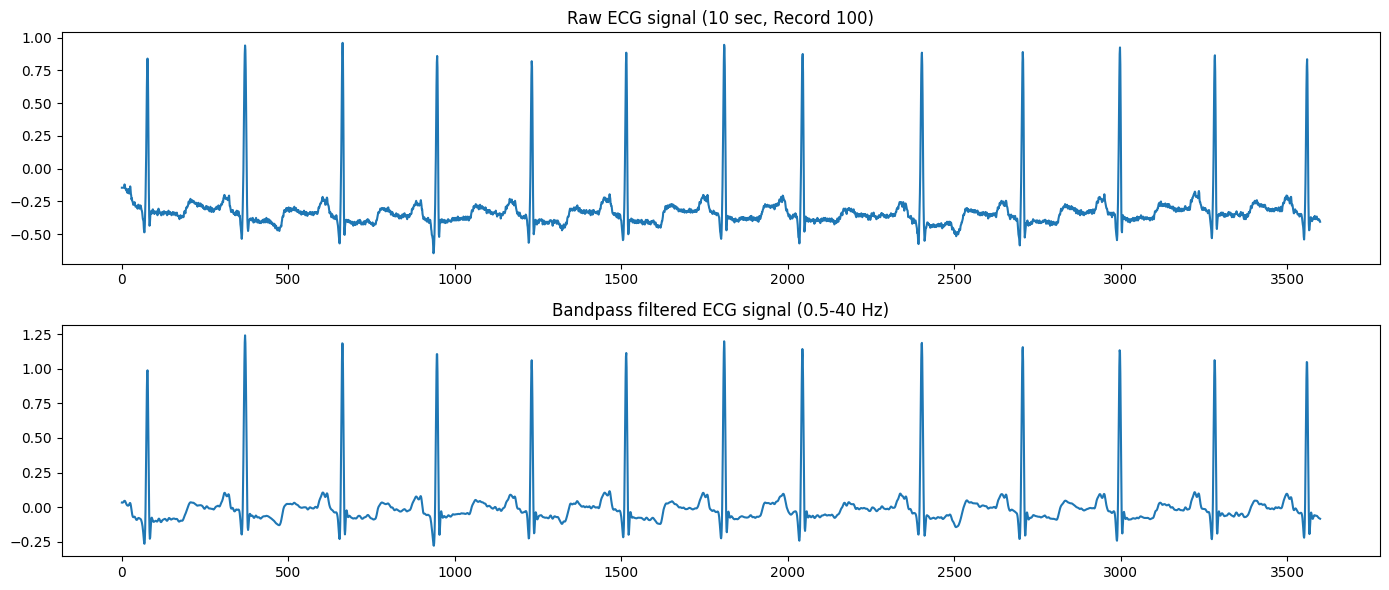

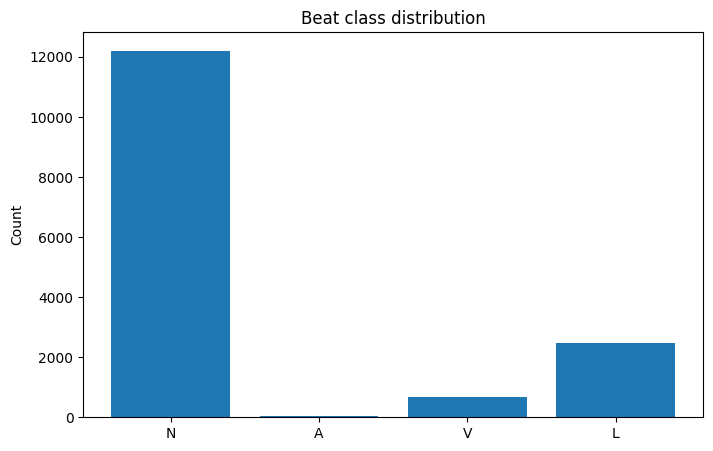

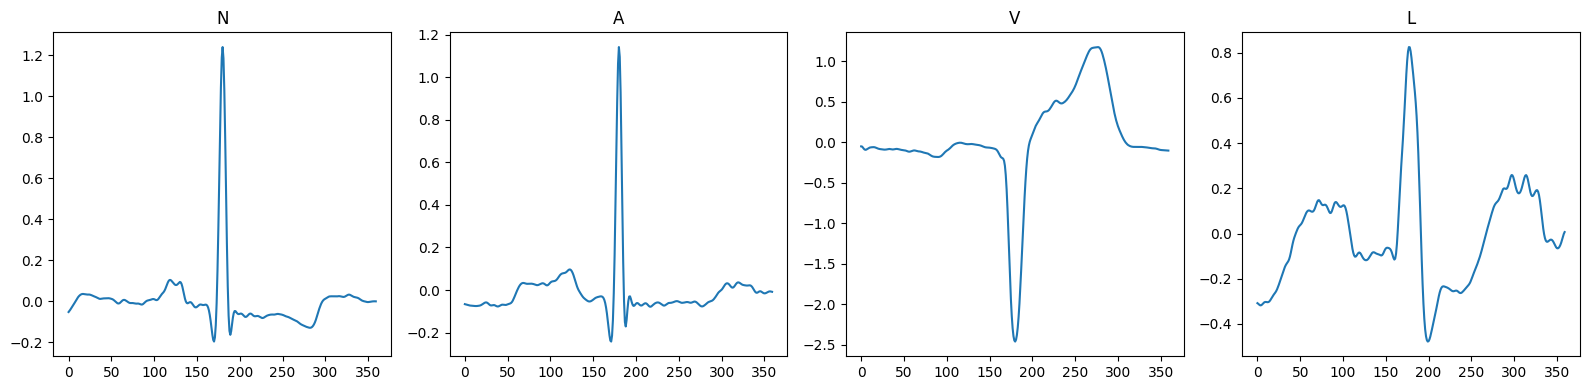

Signal skewness: 4.724996909736277
Signal kurtosis: 27.250781200212984


In [65]:
#  EDA (signal-appropriate)
import matplotlib.pyplot as plt

record_100 = wfdb.rdrecord('mitdb_data/100')
signal_100 = record_100.p_signal[:, 0]
filtered_100 = bandpass_filter(signal_100, record_100.fs)

fig, axes = plt.subplots(2, 1, figsize=(14, 6))
axes[0].plot(signal_100[:3600])
axes[0].set_title('Raw ECG signal (10 sec, Record 100)')
axes[1].plot(filtered_100[:3600])
axes[1].set_title('Bandpass filtered ECG signal (0.5-40 Hz)')
plt.tight_layout()
plt.savefig('ecg_raw_vs_filtered.png')
plt.show()

plt.figure(figsize=(8,5))
labels_unique, counts = np.unique(y_encoded, return_counts=True)
label_names = ['N', 'A', 'V', 'L']
plt.bar(label_names, counts)
plt.ylabel('Count')
plt.title('Beat class distribution')
plt.savefig('ecg_class_distribution.png')
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(16,4))
for i, cls in enumerate(np.unique(y_encoded)):
    idx = np.where(y_encoded == cls)[0][0]
    axes[i].plot(X_signal_valid[idx])
    axes[i].set_title(label_names[i])
plt.tight_layout()
plt.savefig('ecg_sample_waveforms.png')
plt.show()

from scipy.stats import kurtosis, skew
print("Signal skewness:", skew(filtered_100))
print("Signal kurtosis:", kurtosis(filtered_100))

RR intervals (sec) - first 10: [0.16388889 0.81388889 0.81111111 0.78888889 0.79166667 0.78888889
 0.81666667 0.65277778 0.99444444 0.84444444]
Mean RR: 0.7943161265092633 SDNN: 0.05058434099145012
       peak_amp    peak_pos     energy  zero_crossings
label                                                 
0      1.434382  179.434480  23.754443        8.605815
1      1.256090  178.000000  11.774245        7.142857
2      1.511486  179.307918  88.517484        6.112903
3      1.802236  179.101606  65.012996        5.700402


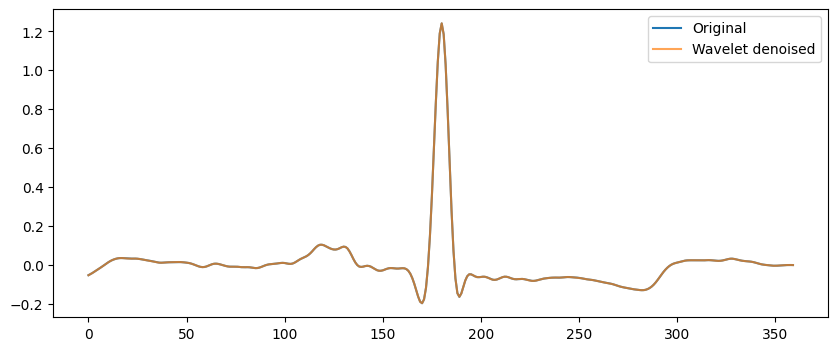

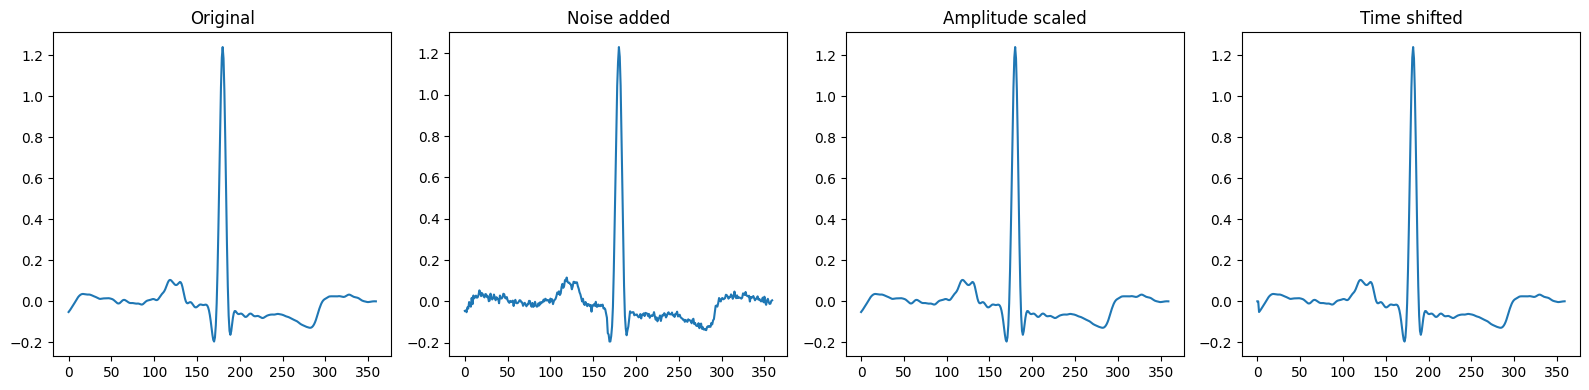

In [66]:
# Feature Engineering / Selection / Extraction / Noise Removal / Augmentation
!pip install PyWavelets -q

from scipy.signal import find_peaks
import numpy as np

def extract_hrv_features(record_name):
    record = wfdb.rdrecord(f'mitdb_data/{record_name}')
    annotation = wfdb.rdann(f'mitdb_data/{record_name}', 'atr')
    rr_intervals = np.diff(annotation.sample) / record.fs
    return rr_intervals

rr_100 = extract_hrv_features('100')
print("RR intervals (sec) - first 10:", rr_100[:10])
print("Mean RR:", rr_100.mean(), "SDNN:", rr_100.std())

def extract_beat_features(window, fs=360):
    peak_amplitude = np.max(window)
    peak_position = np.argmax(window)
    signal_energy = np.sum(window**2)
    zero_crossings = np.sum(np.diff(np.sign(window)) != 0)
    return peak_amplitude, peak_position, signal_energy, zero_crossings

features = []
for i in range(len(X_signal_valid)):
    feats = extract_beat_features(X_signal_valid[i])
    features.append(feats)

import pandas as pd
feat_df = pd.DataFrame(features, columns=['peak_amp', 'peak_pos', 'energy', 'zero_crossings'])
feat_df['label'] = y_encoded
print(feat_df.groupby('label').mean())

def wavelet_denoise(signal, wavelet='db4', level=1):
    import pywt
    coeffs = pywt.wavedec(signal, wavelet, level=level)
    sigma = np.median(np.abs(coeffs[-1])) / 0.6745
    threshold = sigma * np.sqrt(2 * np.log(len(signal)))
    coeffs[1:] = [pywt.threshold(c, threshold, mode='soft') for c in coeffs[-len(coeffs)+1:]]
    denoised = pywt.wavedec(signal, wavelet, level=level)
    return pywt.waverec(coeffs, wavelet)

sample_signal = X_signal_valid[0]
denoised_sample = wavelet_denoise(sample_signal)

plt.figure(figsize=(10,4))
plt.plot(sample_signal, label='Original')
plt.plot(denoised_sample[:len(sample_signal)], label='Wavelet denoised', alpha=0.7)
plt.legend()
plt.savefig('ecg_wavelet_denoise.png')
plt.show()

def augment_signal(signal):
    noise = np.random.normal(0, 0.01, len(signal))
    noisy = signal + noise
    scaled = signal * np.random.uniform(0.9, 1.1)
    shift = np.random.randint(-10, 10)
    shifted = np.roll(signal, shift)
    return noisy, scaled, shifted

noisy_sig, scaled_sig, shifted_sig = augment_signal(X_signal_valid[0])
fig, axes = plt.subplots(1, 4, figsize=(16,4))
axes[0].plot(X_signal_valid[0]); axes[0].set_title('Original')
axes[1].plot(noisy_sig); axes[1].set_title('Noise added')
axes[2].plot(scaled_sig); axes[2].set_title('Amplitude scaled')
axes[3].plot(shifted_sig); axes[3].set_title('Time shifted')
plt.tight_layout()
plt.savefig('ecg_augmented.png')
plt.show()


### Data Acquisition, Cleaning, Preprocessing and Analysis on Multimodal Medical Data

This report summarizes the work done across four different types of medical data: Tabular (Diabetes), Textual (Medical Transcriptions), Image (Chest X-Rays), and Signal (ECG). For each dataset, I performed data acquisition, cleaning, preprocessing, exploratory analysis, and feature engineering.

### Tabular Data - Pima Indians Diabetes Dataset

**What the dataset is:** 768 patient records with 8 health measurements (Pregnancies, Glucose, Blood Pressure, Skin Thickness, Insulin, BMI, Diabetes Pedigree Function, Age) and a target column showing whether the patient has diabetes (Outcome: 0 = No, 1 = Yes).

**Acquisition & Inspection:** The dataset has no missing values according to pandas, and no duplicate rows. However, on closer inspection, I found that columns like Insulin and Skin Thickness had a large number of values repeated exactly (e.g., 236 rows had Insulin = 102.5, and 138 rows had Insulin = 169.5). This is a strong sign that someone had already filled in missing values using median imputation before I received the file, without documenting it. In a real clinical dataset, a BMI or Blood Pressure of 0 is medically impossible, so this kind of hidden imputation is exactly the "missingness encoded as valid-looking values" problem the assignment talks about.

**Cleaning:** I checked for PHI (patient names, IDs, addresses) - this dataset has none, since it is a de-identified public research dataset. I also flagged the suspected pre-imputed values and checked all columns against medically plausible ranges (e.g., Age between 18-100, Glucose between 40-300).

**Preprocessing:** I split the data into training (614 rows) and testing (154 rows) sets, then scaled all features using StandardScaler so they are on the same numeric scale, and converted them into PyTorch tensors so they are ready to be fed into a model.

**Statistical Testing:**
- **T-test:** Every single feature showed a statistically significant difference between diabetic and non-diabetic patients (all p-values well below 0.05). Glucose had the strongest difference (p ≈ 8.3e-42), which makes clinical sense since glucose level is the most direct indicator of diabetes.
- **Chi-square test:** I grouped patients into BMI categories (Underweight, Normal, Overweight, Obese) and tested whether BMI category is related to diabetes outcome. The result (p ≈ 9.1e-16) confirms a strong relationship - obese patients are far more likely to have diabetes.
- **ANOVA:** I grouped patients by age group (Young, Adult, Middle-Age, Senior) and tested whether average glucose level differs across age groups. The result (p ≈ 7.6e-13) confirms glucose levels do differ significantly with age.

**EDA:** I plotted histograms, boxplots (split by outcome), a correlation heatmap, and a pairplot. Insulin and DiabetesPedigreeFunction were the most skewed features (skewness of 3.0 and 1.9), meaning most patients have low values with a few extreme outliers - typical for medical measurements.

**Feature Engineering:** I created two new features - Glucose × BMI interaction and Insulin/Glucose ratio - both of which turned out to be strong predictors when I ran feature selection (Glucose×BMI had the highest F-score of all features). I also removed outliers using the IQR method, reduced dimensionality with PCA, and balanced the imbalanced classes (500 non-diabetic vs 268 diabetic) using SMOTE oversampling, bringing both classes to 500 each.

### Textual Data - MTSamples Medical Transcriptions

**What the dataset is:** 4999 real medical transcription notes across different specialties (Cardiology, Bariatrics, Allergy/Immunology, etc.), along with the specialty label, sample name, and keywords for each note.

**Acquisition & Inspection:** 33 transcriptions and 1068 keyword entries were missing. More importantly, I found 2641 duplicate transcriptions out of 4999 rows - meaning over half the "unique" samples were actually copies of the same note (common with template-based consult notes). This matters a lot because if these duplicates aren't removed before training a model, the same text could end up in both the training and test sets, making the model look better than it really is.

**Cleaning:** I removed rows with missing transcriptions and dropped duplicates, bringing the dataset down to 2357 usable rows. For PHI removal, I wrote a function to detect and mask dates, doctor names, phone numbers, and MRN (Medical Record Number) patterns using regular expressions, since clinical text commonly contains this kind of sensitive information even in "de-identified" datasets. I also lowercased the text and removed unusual characters as part of standard text cleaning.

**Preprocessing:** I converted the specialty labels into numbers, then tokenized the transcription text into sequences of numbers using a vocabulary of 10,000 words, and padded every sequence to a fixed length of 300 tokens - the standard format needed before feeding text into a neural network.

**EDA:** I plotted the most common medical specialties, the distribution of word counts per note, and a word cloud of the most frequent terms.

**Feature Engineering:** I removed common stopwords ("the", "is", "and", etc.) and used TF-IDF to find the most important words across all notes. The top terms - "patient", "right", "left", "history", "normal", "pain", "procedure", "diagnosis" - are exactly the kind of vocabulary you'd expect in real clinical notes, confirming the cleaning worked correctly.

### Image Data - Chest X-Ray (Pneumonia) Dataset

**What the dataset is:** Chest X-ray images split into NORMAL and PNEUMONIA classes, across train (5216 images), test (624 images), and validation (16 images) folders.

**Acquisition & Inspection:** The training set is imbalanced - 1341 NORMAL images vs 3875 PNEUMONIA images (about 3x more pneumonia cases). The validation folder only has 16 images total, which is a well-known limitation of this specific dataset online - too small to reliably validate a model during training. Image sizes also varied a lot, from 384x127 pixels up to 2373x2663 pixels, so every image needs resizing before it can be used in a model.

**Cleaning:** I checked for embedded metadata (EXIF data) in the images, since imaging metadata can sometimes leak sensitive information like device ID or timestamps. Out of 200 sampled images, 105 (about half) had embedded metadata that needed to be stripped. I also checked for blank or corrupted images (none found) and compared pixel intensity statistics between the two classes - pneumonia images showed more variation in brightness (std ~54) compared to normal images (std ~62), which reflects the visible lung opacities/infiltrates that pneumonia causes on an X-ray.

**Preprocessing:** I converted every image to grayscale, resized to 224x224 pixels, normalized the pixel values, and converted them into PyTorch tensors - the standard input format for an image classification model.

**EDA:** I visualized sample images from both classes side by side, plotted the class balance and split sizes, and looked at the distribution of average pixel brightness across images from each class.

**Feature Engineering & Augmentation:** I applied denoising (to reduce sensor/scan noise) and CLAHE contrast enhancement (to make lung details more visible) as feature engineering steps. For augmentation - since medical imaging datasets are often small and imbalanced - I applied random rotation, horizontal flip, small translation, and brightness/contrast changes to artificially increase the diversity of training images without changing what the image actually shows medically.

## Signal Data - MIT-BIH Arrhythmia Database (ECG)

**What the dataset is:** 48 half-hour ECG recordings from real patients, each sampled at 360 Hz with two signal leads (MLII and V5), along with expert cardiologist annotations marking every single heartbeat type (Normal, Atrial premature beat, Premature ventricular contraction, etc.).

**Acquisition & Inspection:** Record 100, for example, has 650,000 samples per lead (about 30 minutes of recording) and 2274 annotated beats, of which 2239 are Normal beats, 33 are Atrial premature beats, and 1 is a PVC.

**Cleaning:** I checked all records for missing values (none found), flat-line segments, and signal saturation/clipping (very minimal). I also checked the header "comments" field, which - unlike the diabetes or X-ray datasets - actually contains patient age, sex, and medication names (e.g., "69 M... Aldomet, Inderal"). While this isn't a direct identifier like a name, it is sensitive clinical metadata that should be handled carefully, since combining age + sex + medication could theoretically help re-identify someone in a small dataset.

**Preprocessing:** I applied a bandpass filter (0.5-40 Hz) to remove noise outside the useful ECG frequency range, then extracted a 1-second window (360 samples) around every annotated heartbeat, giving 22,008 labeled beat windows from the first 10 records. After keeping only the medically meaningful beat types (Normal, Atrial, Ventricular, Left bundle branch block) and discarding non-beat markers, I was left with 15,424 clean, labeled beat windows ready for a model.

**EDA:** I compared the raw vs filtered signal, plotted the class distribution of beat types (heavily dominated by Normal beats), plotted sample waveforms for each beat type, and measured the signal's statistical shape - it is highly right-skewed (skewness ≈ 4.7) and sharply peaked (kurtosis ≈ 27.3), which makes sense since ECG is mostly a flat baseline with brief, sharp spikes at each heartbeat.

**Feature Engineering:** I calculated RR intervals (time between heartbeats) - average about 0.79 seconds, which corresponds to a normal resting heart rate of around 75 beats per minute. I also extracted per-beat features like peak amplitude, energy, and zero-crossings, which clearly separated Normal beats from Ventricular beats (PVCs had much higher energy and fewer zero-crossings, matching their known wider, more abnormal shape). For noise removal I used wavelet denoising, and for augmentation I added small amounts of random noise, amplitude scaling, and time shifts to each beat window, which is a common technique to make ECG models more robust to real-world signal variation.

### Why Healthcare Data Needs Extra Rigor

Working across all four data types showed the same handful of problems again and again, just in different forms:

- **Missingness disguised as real values:** In the diabetes dataset, missing Insulin/BMI values had already been silently replaced with numbers that look completely normal. If you don't check for this, you might trust fake data without realizing it.
- **Class imbalance:** Every single dataset had it - fewer diabetic patients than non-diabetic, fewer Normal X-rays than Pneumonia, and very few rare heartbeat types compared to Normal beats. In healthcare, missing the rare class (the actual disease) is far more costly than in most other domains, so this needs deliberate handling (like SMOTE or careful evaluation metrics), not just accuracy.
- **Privacy (PHI):** Even "de-identified" datasets aren't always fully safe - the medical transcription notes needed regex-based PHI scrubbing, the X-ray images carried embedded metadata, and the ECG records had age, sex, and medication info sitting in plain text.
- **Signal/data noise:** ECG signals need frequency filtering to remove noise before any meaningful feature extraction is possible, and X-ray images vary wildly in size, brightness, and quality depending on how they were captured - generic datasets rarely require this level of modality-specific cleaning before you can even start modeling.

## Conclusion

Across all four modalities, the same lesson kept repeating: healthcare data looks clean on the surface but almost always hides problems that only show up once you actually inspect it closely - repeated "imputed" values, hidden patient metadata, duplicate records, and imbalanced classes. Cleaning and preprocessing this data properly, before any modeling is attempted, is not optional - it directly affects whether the resulting model can be trusted in a clinical setting.